# 07 · CRECl groups, constraint and motif energies of p2p pairs (Fig 4A-D)

1. **CRECl groups**: the 89 mouse CRECls of the figure in 13 groups by their dynamics (the paper's c and I-XII), ordered by
   group and, within a group, by maximal accessibility.
2. **Figs 4A-C**: accessibility of the CRECls over the 40 states (A), bases under constraint (phyloP >= 2.27) in the
   central 300 bp of their p2p pdCREs (B), and their enrichment for 11 motifs (C).
3. **Fig 4D**: for one-to-one p2p pairs in CRECls enriched for a motif (> 2 in either species), the motif energy of the
   two pdCREs in percentile bins, as counts and log2 observed / expected.

Figs 4A-C come out as in the paper only in the Jupyter R kernel: under Rscript, ComplexHeatmap lays the page out
differently. In the paper, the labels of Fig 4 were edited by hand: group codes as c, I-XII, "phyloP05" as "Bases
conserved", "Sox3(m3)" / "Cdx(m5)" as "Sox3" / "Cdx", and the axis titles of D.

## Setup

In [1]:
source("../R/setup.R")
suppressPackageStartupMessages({
    library(ComplexHeatmap)
    library(circlize)
})
ht_opt$message = FALSE
O1 = file.path(OUT_DIR, "01_crecls")
O2 = file.path(OUT_DIR, "02_states")
O3 = file.path(OUT_DIR, "03_crecl_homology")
O4 = file.path(OUT_DIR, "04_motifs")
O5 = file.path(OUT_DIR, "05_orthology")

## 1. CRECl groups

The grouping of the 89 CRECls (the variable, pan-gastrulation and erythroid CRECls; no weak or small ones), by code; the
paper prints the codes as c, I-XII. The CRECls are ordered by group (alphabetically in the en_US locale: c, vA, vA1, vB,
vB1, vB12, vB2, vC, vD, veZ, vZ, vZ1, vZb) and, within a group, by their maximal accessibility over the states.

In [2]:
mm_crecl_grouping = c(`29` = "c", `38` = "c", `67` = "c", `68` = "c", `71` = "c",
`72` = "c", `69` = "vA", `37` = "vA", `64` = "vA", `61` = "vA", `58` = "vA", `63` = "vA",
`65` = "vA", `57` = "vA", `62` = "vA", `49` = "vA1",
`60` = "vA1", `48` = "vA1", `59` = "vA1", `53` = "vA1", `84` = "vB", `82` = "vB",
`79` = "vB", `80` = "vB", `93` = "vB", `86` = "vB", `85` = "vB",
`88` = "vB", `11` = "vB1",
`77` = "vB1", `78` = "vB1", `76` = "vB1", `55` = "vB2",
`36` = "vB2", `34` = "vB2", `33` = "vB2", `41` = "vB2", `54` = "vB2",
`35` = "vB2", `46` = "vB12", `50` = "vB12", `51` = "vB12", `42` = "vB2",
`98` = "vC", `99` = "vC", `97` = "vC", `89` = "vD", `90` = "vD",
`40` = "vD", `100` = "vD", `94` = "vD", `96` = "vD",  `95` = "vD", `2` = "vZ", `32` = "vZb", `15` = "vZ",
`28` = "vZ", `6` = "vZ", `14` = "vZ", `30` = "vZ", `1` = "vZ",
`4` = "vZ", `18` = "vZ", `3` = "vZ", `16` = "vZ", `10` = "vZ",
`8` = "vZ", `25` = "vZb", `92` = "veZ", `13` = "vZ", `27` = "vZb",
`31` = "vZb", `12` = "vZ", `9` = "veZ", `7` = "veZ", `24` = "vZb",
                      `19` = "vZb",
                      `20` = "vZb",
                      `21` = "vZb",
                      `22` = "vZb",
                      `23` = "vZb",
`17` = "vZ", `26` = "vZb", `91` = "veZ", `45` = "vZ1", `73` = "vZ1",
`75` = "vZ1", `44` = "vZ1", `74` = "vZ1")
mm_crecl = fread(file.path(O1, "mm_crecl.csv")) %>% tibble::deframe()
mm_km = mm_crecl
mm_crecl_sup_legc = fread(file.path(O3, "mm_crecl_sup_legc.csv"), header = TRUE) %>% column_to_rownames("mm_supt")
crecls = names(mm_crecl_grouping)[order(mm_crecl_grouping, apply(mm_crecl_sup_legc, 2, max)[names(mm_crecl_grouping)])]

## 2. Figs 4A-C

A: CRECl accessibility (log, centred per CRECl) over the 40 states, rows coloured by state type. B (box plots under A):
log2(8 + constrained bases) of the p2p pdCREs of each CRECl, filled by the CRECl's median, with dashed lines at 32 and
100 bases. C: enrichment of 11 motifs (notebook 04). Columns: the CRECls by group; C's columns are labelled with the
paper's CRECl numbers (c1-c6 = the pan-gastrulation CRECls, h1-h5 = the erythroid ones).

In [3]:
mm_enrich_df = fread(file.path(O4, "mm_enrich_df.csv"))
mc_type_mm = fread(file.path(O2, "mc_type_mm_smc_sup.csv"))
mm_mclst_types_n = table(mc_type_mm %>% select(sup, cell_type))
mm_mclst_type = colnames(mm_mclst_types_n)[apply(mm_mclst_types_n, 1, which.max)]
names(mm_mclst_type) = rownames(mm_mclst_types_n)
mm_type_key = mc_type_mm %>% select(cell_type, color) %>% distinct()
mm_code_color = mm_type_key$color
names(mm_code_color) = mm_type_key$cell_type
mm_energies = fread(data_path("mm_energies_raw_2025.csv"))
mm_namespace = as.data.frame(fread(data_path("mm_namespace_2025.csv")))
orth_full_wmode = fread(file.path(O5, "orth_full_wmode_wgotg.csv"))
mm_mode = orth_full_wmode$mm_mode
names(mm_mode) = orth_full_wmode$mm_locid
mm_namespace_f = mm_namespace %>% filter(mm_locid %in% orth_full_wmode$mm_locid)
mm_namespace_f$crecl = mm_crecl[mm_namespace_f$mm_locid]
mm_namespace_f$mode = mm_mode[mm_namespace_f$mm_locid]
mmef = mm_energies %>% select(-chrom, -start, -end) %>% column_to_rownames("mm_locid")
mm_namespace_f = mm_namespace_f %>% filter(mm_locid %in% rownames(mmef[rowSums(is.na(mmef)) == 0, ]))
# bases with phyloP242 >= 2.27 in the central 300 bp
mm_loci_cons = fread(data_path("mm_locus_phylop.csv")) %>% select(mm_locid, phyloP05)

motifs = c("Tcf", "Sox3(m3)", "Pou3", "Hoxa1", "Cdx(m5)",
            "Eomes/Tbox", "Mesp2", "Nanog/Sox", "Tead2", "Gata3/6", "Foxa2")
enrich_mat = as.data.frame(
  mm_enrich_df %>%
    select(crecl, motif, enrich) %>%
    pivot_wider(names_from = motif, values_from = enrich) %>%
    column_to_rownames("crecl")
)[crecls, motifs]
mm_crecls = mm_crecl_sup_legc[rownames(mm_crecl_sup_legc), crecls]
mm_renaming = c(c(`75` = "1", `74` = "1.1", `45` = "2", `73` = "3", `44` = "4",
`60` = "5", `59` = "5.1", `49` = "5.2", `48` = "5.3", `89` = "6",
`90` = "6.1", `100` = "6.2", `40` = "7", `97` = "8", `98` = "8.1",
`99` = "8.2", `4` = "9", `3` = "9.1", `14` = "9.2", `18` = "10",
`15` = "10.1", `6` = "10.2", `2` = "11", `1` = "11.1", `30` = "12",
`32` = "12.1", `28` = "12.2", `77` = "13", `78` = "13.1", `76` = "14",
`11` = "15"),
c(`34` = "16", `33` = "16.1", `35` = "16.2", `46` = "16.3", `41` = "16.4",
`54` = "17", `55` = "17.1", `53` = "17.2", `37` = "17.3", `51` = "17.4",
`42` = "18", `36` = "18.1", `50` = "19", `57` = "20", `64` = "20.1",
`62` = "20.2", `65` = "20.3", `63` = "20.4", `58` = "21", `69` = "21.1",
`61` = "22", `86` = "23", `85` = "23.1", `88` = "23.2", `82` = "24",
`93` = "25", `96` = "26", `95` = "26.1", `94` = "26.2", `79` = "27",
`80` = "27.1", `84` = "28", `16` = "29", `8` = "30", `7` = "30.1",
`10` = "30.2", `9` = "30.3", `12` = "31", `13` = "31.1", `17` = "31.2",
`24` = "32", `25` = "32.1", `26` = "32.2", `31` = "32.3", `27` = "32.4",
`92` = "33", `91` = "33.1"),
c(`67` = "c1", `38` = "c2", `29` = "c3", `72` = "c4",
`68` = "c5", `71` = "c6"),
c(`19` = "h1", `20` = "h2", `21` = "h3", `22` = "h4",
`23` = "h5")
               )
enrich_mat_rn = enrich_mat[crecls, motifs]
enrich_mat_rn = enrich_mat_rn[intersect(rownames(enrich_mat_rn), names(mm_renaming)),]
rownames(enrich_mat_rn) = mm_renaming[rownames(enrich_mat_rn)]

# log2(8 + constrained bases) of the p2p pdCREs of each CRECl
abs_shades_blue = colorRampPalette(
  c("white", "white", "cornflowerblue", "blue", "darkblue", "black"))(1000)
tobar = mm_namespace_f %>%
  mutate(crecl = mm_km[mm_locid]) %>%
  filter(!is.na(crecl)) %>%
  left_join(mm_loci_cons, by = "mm_locid") %>%
  filter(mode == "p2p") %>%
  mutate(
    g = factor(mm_crecl_grouping[as.character(crecl)]),
    crecl = factor(crecl, levels = crecls)
  ) %>% mutate(phyloP05=log2(8+phyloP05)) %>%
  filter(!is.na(g)) %>%
  filter(!is.na(crecl))

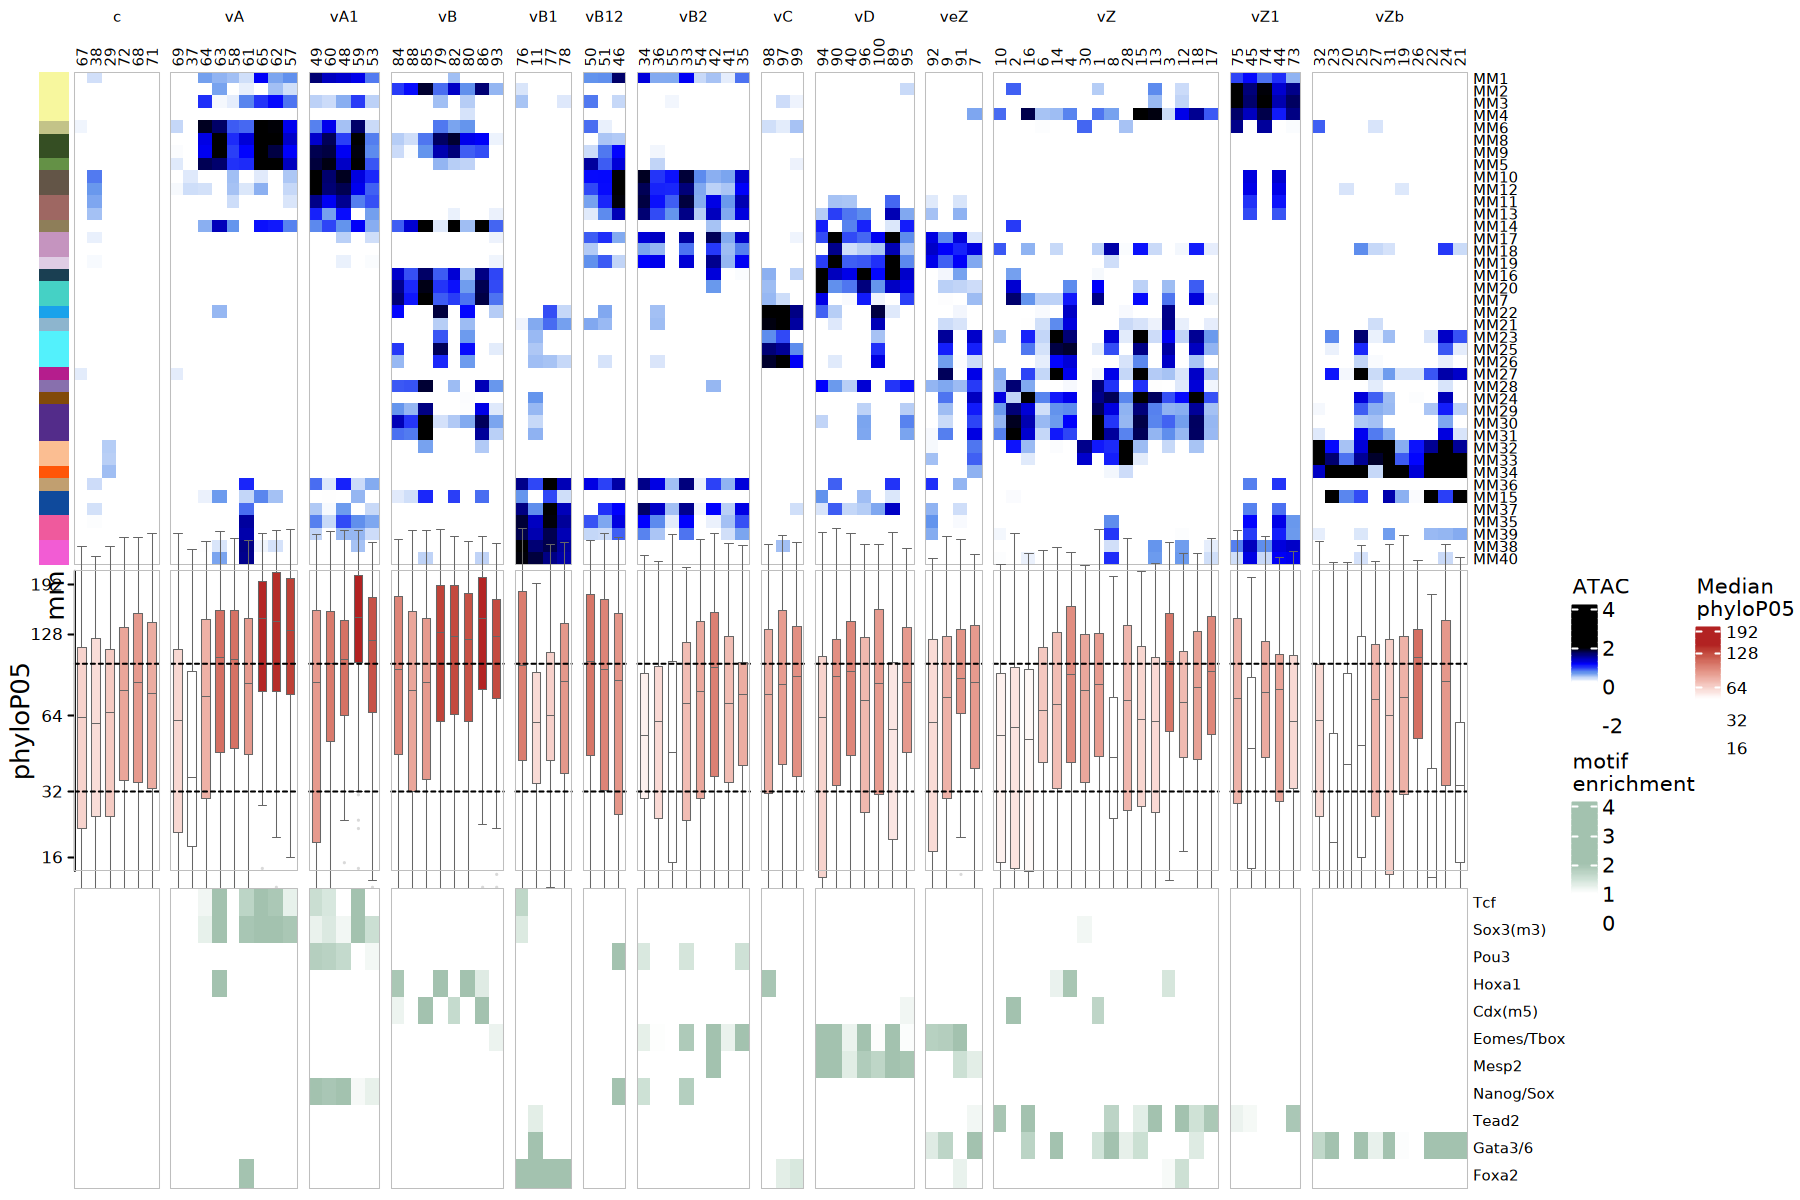

In [4]:
cols = colnames(mm_crecls)
tobar_list = split(tobar$phyloP05, tobar$crecl)
tobar_list = tobar_list[cols]
medians = sapply(tobar_list, median, na.rm = TRUE)
box_col_fun = colorRamp2(
  c(min(medians, na.rm=TRUE), log2(8+50), max(medians, na.rm=TRUE)),
  c("white", "white", "firebrick")
)
bottom_anno = HeatmapAnnotation(
  phyloP05 = anno_boxplot(
    tobar_list,
    ylim = c(log2(8+16), log2(8+128+64)),
    gp = gpar(fill = box_col_fun(medians), col = "gray40", lwd = 0.5),
    pt_gp = gpar(col = "gray50", alpha = 0.3),
    size = unit(0.5, "mm"),
    height = unit(2, "inch"),
    border = FALSE,
    axis_param = list(
      at = log2(8 + c(16, 32, 64, 128, 128+64)),
      labels = c(16, 32, 64, 128, 192)
    )
  ),
  annotation_name_side = "left"
)
options(repr.plot.width=12, repr.plot.height=8)
hm_top = Heatmap(
  t(t(mm_crecls) - colMeans(mm_crecls)),
  cluster_rows      = FALSE,
  cluster_columns   = FALSE,
  show_row_names    = TRUE,
  show_column_names = TRUE,
  column_names_side = "top",
  left_annotation   = ComplexHeatmap::rowAnnotation(
    show_legend = FALSE,
    mm  = mm_mclst_type[rownames(mm_crecls)],
    col = list(mm = mm_code_color)
  ),
  col = circlize::colorRamp2(
    c(-2, seq(-0.2, 2, l = 998), 3),
    abs_shades_blue
  ),
  row_title         = NULL,
  column_split      = mm_crecl_grouping[colnames(mm_crecls)],
  column_gap        = unit(2, "mm"),
  border            = TRUE,
  border_gp         = grid::gpar(col = "grey", lwd = 0.5),
  row_title_gp      = grid::gpar(fontfamily = "ArialMT", fontsize = 7),
  column_title_gp   = grid::gpar(fontfamily = "ArialMT", fontsize = 7),
  row_names_gp      = grid::gpar(fontfamily = "ArialMT", fontsize = 7),
  column_names_gp   = grid::gpar(fontfamily = "ArialMT", fontsize = 7),
  use_raster        = TRUE,
  heatmap_legend_param = list(title = "ATAC"),
  bottom_annotation = bottom_anno
)
bot_col_fun = circlize::colorRamp2(
  breaks = c(0, 1, 1.5, 2, 4),
  colors = c("white", "white", "#cce0d4", "#a3c2af", "#a3c2af")
)
hm_bot = Heatmap(
  t(enrich_mat_rn),
  cluster_rows      = FALSE,
  cluster_columns   = FALSE,
  show_row_names    = TRUE,
  show_column_names = FALSE,
  col               = bot_col_fun,
  height            = unit(2, "inch"),
  row_title         = NULL,
  column_split      = mm_crecl_grouping[colnames(mm_crecls)],
  column_gap        = unit(2, "mm"),
  border            = TRUE,
  border_gp         = grid::gpar(col = "grey", lwd = 0.5),
  row_title_gp      = grid::gpar(fontfamily = "ArialMT", fontsize = 7),
  row_names_gp      = grid::gpar(fontfamily = "ArialMT", fontsize = 7),
  use_raster        = TRUE,
  heatmap_legend_param = list(
    title = "motif\nenrichment",
    at = c(0, 1, 2, 3, 4)
  )
)
ht_list = hm_top %v% hm_bot
box_legend = Legend(
  col_fun = box_col_fun,
  title = "Median\nphyloP05",
  title_gp = gpar(fontsize = 10, fontface = "bold"),
  labels_gp = gpar(fontsize = 8),
  at = log2(8 + c(16, 32, 64, 128, 192)),
  labels = c("16", "32", "64", "128", "192")
)
draw(ht_list,
     ht_gap = unit(3, "mm"),
     annotation_legend_list = list(box_legend))
num_splits = length(unique(mm_crecl_grouping[colnames(mm_crecls)]))
for(i in 1:num_splits) {
  decorate_annotation("phyloP05", slice = i, {
    grid::grid.lines(y = unit(log2(8+32), "native"), gp = grid::gpar(lty = 2))
    grid::grid.lines(y = unit(log2(8+100), "native"), gp = grid::gpar(lty = 2))
    grid::grid.rect(gp = grid::gpar(col = "grey", lwd = 0.5, fill = NA))
  })
}

## 3. Fig 4D

Rows: one-to-one p2p pairs whose mouse or rabbit CRECl is enriched for the motif (> 2), from both sides: mouse pdCREs in
CRECls with exactly one rabbit ortholog, and rabbit pdCREs in CRECls with exactly one mouse ortholog (mouse loci already
counted, and those with several such rabbit orthologs, are left out). The class of a pair is the mouse one. Each energy is
binned by the number of percentile thresholds (1-99) of the CRECl pdCREs it exceeds: on mouse-side rows both energies
against the mouse thresholds, on rabbit-side rows against the rabbit ones. Bins: 0-93, 93-97 and 97-100 thresholds
exceeded (the last = above the 98th percentile). Colour: log2 observed / expected count per motif. A locus counts as having
complete energies only with its CG and GC values, which leaves out 331 rabbit loci.

In [5]:
orth_full = orth_full_wmode
mm = fread(data_path("mm_emb_locif.csv")) %>% left_join(fread(data_path("mm_namespace_2025.csv")), by = c("chrom", "start", "end"))
oc = fread(data_path("oc_emb2_locif.csv")) %>% left_join(fread(data_path("oc_namespace_2025.csv")), by = c("chrom", "start", "end"))
mm_crecl_df = fread(file.path(O1, "mm_crecl.csv")); oc_crecl_df = fread(file.path(O1, "oc_crecl.csv"))
mm_km = as.character(mm_crecl_df$kmc); names(mm_km) = mm_crecl_df$locid
oc_km = as.character(oc_crecl_df$kmc); names(oc_km) = oc_crecl_df$locid
oc_enrich_df = fread(file.path(O4, "oc_enrich_df.csv"))

# complete energies: the CG and GC values too
mm_energies_full = fread(data_path("mm_energies_raw_2025.csv")) %>%
    left_join(fread(data_path("mm_CG.csv")) %>% select(mm_locid, CG=seq.CG_500_mean_new), by = "mm_locid") %>%
    left_join(fread(data_path("mm_gc.csv")) %>% select(mm_locid, GC=gc_content), by = "mm_locid")
oc_energies_full = fread(data_path("oc_energies_raw_2025.csv")) %>%
    left_join(fread(data_path("oc_CG.csv")) %>% select(oc_locid, CG=seq.CG_500_mean_new), by = "oc_locid") %>%
    left_join(fread(data_path("oc_gc.csv")) %>% select(oc_locid, GC=gc_content), by = "oc_locid")
mmef = mm_energies_full %>% select(-chrom, -start, -end) %>% column_to_rownames("mm_locid")
ocef = oc_energies_full %>% select(-chrom, -start, -end) %>% column_to_rownames("oc_locid")
mm_notss = mm %>% filter(mm_locid %in% rownames(mmef[rowSums(is.na(mmef)) == 0, ]))
oc_notss = oc %>% filter(oc_locid %in% rownames(ocef[rowSums(is.na(ocef)) == 0, ]))

# the motifs of the figure; 22 motifs x 41 species only set the row limit for repeated rabbit-side loci (below)
selected_motifs = c("Tcf", "Sox3(m3)", "Pou3", "Tead2", "Cdx(m5)", "Eomes/Tbox", "Mesp2", "Nanog/Sox", "Hoxa1", "Gata3/6", "Foxa2")
n_motifs_long = 22
n_species_long = 41

# percentile thresholds per motif over the CRECl pdCREs with complete energies
mm_energies_mm_km = mmef[intersect(names(mm_km), rownames(mmef[mm_notss$mm_locid, ])), selected_motifs]
oc_energies_oc_km = ocef[intersect(names(oc_km), rownames(ocef[oc_notss$oc_locid, ])), selected_motifs]
mm_thr = sapply(selected_motifs, function(m) quantile(mm_energies_mm_km[[m]], (1:99) * 0.01))
oc_thr = sapply(selected_motifs, function(m) quantile(oc_energies_oc_km[[m]], (1:99) * 0.01))
bin_of = function(e, motif, thr) vapply(seq_along(e), function(i) sum(e[i] > thr[, motif[i]]), 0)

In [6]:
all_loc_e_orth_km = orth_full %>% mutate(mm_km = mm_km[mm_locid], oc_km = oc_km[oc_locid]) %>%
    full_join(mm_energies_full %>% select(mm_locid, all_of(selected_motifs)), by = "mm_locid", relationship = "many-to-many") %>%
    full_join(oc_energies_full %>% select(oc_locid, all_of(selected_motifs)), by = "oc_locid", relationship = "many-to-many", suffix = c("_mm", "_oc")) %>%
    distinct()
long_side = function(ekm, thr) {
    ekm %>% select(mm_locid, imgstat, mm_km, oc_km, oc_locid, paste0(selected_motifs, "_mm"), paste0(selected_motifs, "_oc")) %>%
        pivot_longer(!c(mm_locid, imgstat, mm_km, oc_km, oc_locid), names_to = "motif_spec", values_to = "e") %>%
        separate_wider_regex(motif_spec, c(motif = ".*?", "_", spec = ".*$")) %>%
        mutate(bin = bin_of(e, motif, thr)) %>%
        left_join(mm_enrich_df %>% filter(motif %in% selected_motifs) %>% mutate(mm_km=as.character(crecl)) %>% select(mm_km, motif, mm_enrich=enrich), by = c("mm_km", "motif")) %>%
        left_join(oc_enrich_df %>% filter(motif %in% selected_motifs) %>% mutate(oc_km=as.character(crecl)) %>% select(oc_km, motif, oc_enrich=enrich), by = c("oc_km", "motif"))
}
# both sides; imgstat = the mouse class
mm2oc_ekm = all_loc_e_orth_km %>% filter(!is.na(mm_km)) %>% filter(!is.na(mm_peak_id)) %>% mutate(imgstat=mm_mode) %>% filter(mm_orth_tot==1) %>% filter(imgstat != "NA")
oc2mm_ekm = all_loc_e_orth_km %>% filter(!is.na(oc_km)) %>% filter(!is.na(oc_peak_id)) %>% mutate(imgstat=mm_mode) %>% filter(oc_orth_tot==1) %>% filter(imgstat != "NA")
dups = c(intersect(mm2oc_ekm$mm_locid, oc2mm_ekm$mm_locid),
         names(which(table(oc2mm_ekm$mm_locid) * n_motifs_long * n_species_long > 1000)))
mm2oc_longer = rbind(long_side(mm2oc_ekm %>% filter(imgstat %in% c("p2p", "p2w", "p2b")), mm_thr),
                     long_side(oc2mm_ekm %>% filter(!mm_locid %in% dups) %>% filter(imgstat %in% c("p2p", "p2w", "p2b")), oc_thr))

# the mouse and rabbit bins of each pair
motif_evos = mm2oc_longer %>% select(mm_locid, imgstat, motif, spec, bin, mm_enrich, oc_enrich) %>% pivot_wider(names_from = spec, values_from = bin)
test = motif_evos %>% filter(motif %in% selected_motifs) %>% filter(imgstat=="p2p") %>% filter(!is.na(mm_enrich)) %>% filter(!is.na(oc_enrich)) %>% filter(mm_enrich > 2 | oc_enrich > 2)

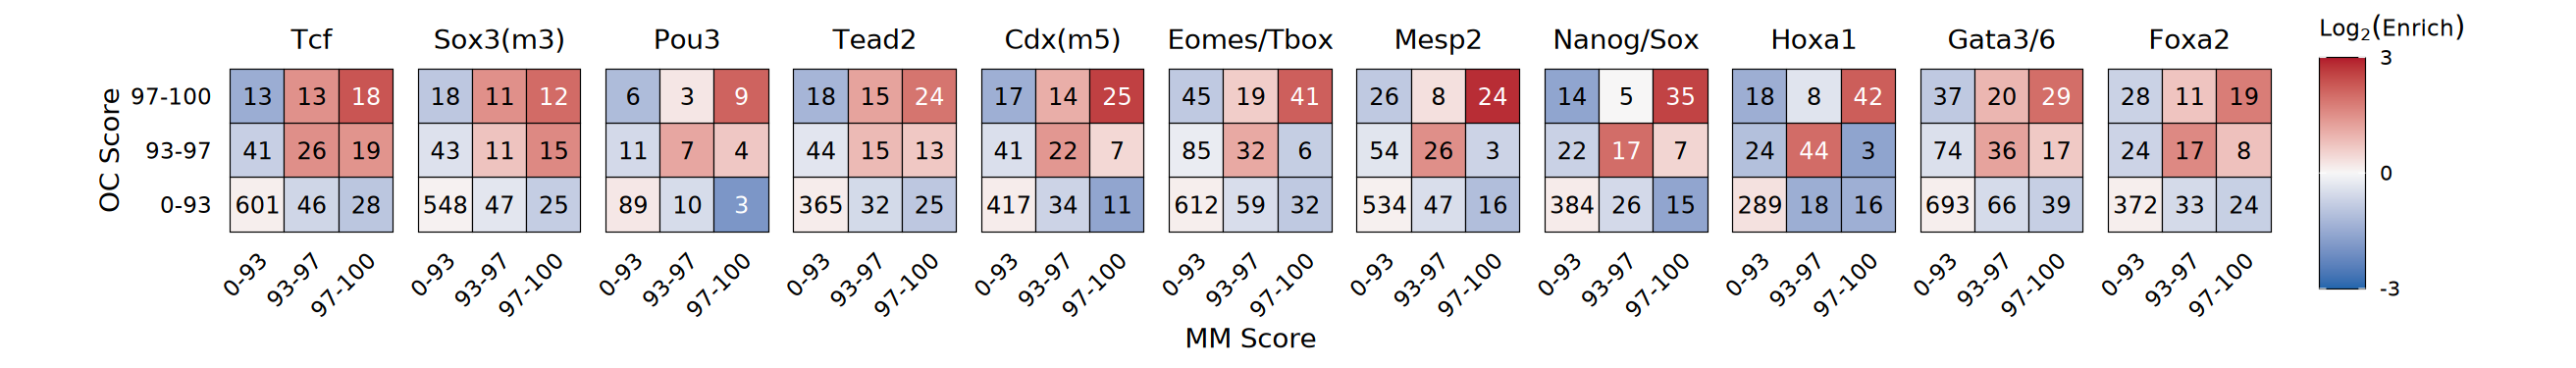

In [7]:
test_binned = test %>% select(mm_locid, motif, mm, oc) %>% mutate(
    mmc=cut(
        mm,
        breaks = rev(c(100, 97, 93, 0)),
        include.lowest = TRUE,
        labels = c("0-93","93-97","97-100")
    )
) %>% mutate(
    occ=cut(
        oc,
        breaks = rev(c(100, 97, 93, 0)),
        include.lowest = TRUE,
        labels = c("0-93","93-97","97-100")
    )
) %>% group_by(motif, mmc, occ) %>% summarise(n=n(), ln=log2(n()), .groups = "drop_last") %>% filter(motif != "Zic(m2)")
max_enrich = 3
options(repr.plot.width = 17.5, repr.plot.height = 2.5)
p = test_binned %>% left_join(
    test_binned %>% group_by(motif, mmc) %>% summarise(occc = sum(n), .groups = "drop_last"), by = c("motif", "mmc")
) %>% left_join(
    test_binned %>% group_by(motif, occ) %>% summarise(mmcc = sum(n), .groups = "drop_last"), by = c("motif", "occ")
) %>% left_join(
    test_binned %>% group_by(motif) %>% summarise(nn = sum(n)), by = "motif"
) %>% mutate(exp=nn*(occc/nn)*(mmcc/nn)) %>% mutate(enrich=log2(n/exp)) %>% filter(motif %in% c("Tcf", "Sox3(m3)", "Pou3", "Tead2",
"Cdx(m5)", "Eomes/Tbox", "Mesp2", "Nanog/Sox", "Hoxa1", "Gata3/6", "Foxa2")) %>% mutate(motif=factor(motif, levels = c("Tcf", "Sox3(m3)", "Pou3", "Tead2",
"Cdx(m5)", "Eomes/Tbox", "Mesp2", "Nanog/Sox", "Hoxa1", "Gata3/6", "Foxa2"))) %>%
mutate(
    enrich_capped = pmax(pmin(enrich, max_enrich), -max_enrich),
    text_color = ifelse(abs(enrich_capped) > (max_enrich * 0.6), "white", "black")
) %>%
ggplot(aes(x=mmc, y=occ, fill=enrich_capped)) +
    geom_tile(color = "black", linewidth = 0.2) +
    geom_text(aes(label = n, color = text_color), size = 4, fontface = "bold") +
    scale_color_identity() +
    scale_fill_gradient2(
      name = expression(Log[2]("Enrich")),
      low = "#2166AC",
      mid = "#F7F7F7",
      high = "#B2182B",
      midpoint = 0,
      breaks = c(-max_enrich, 0, max_enrich),
      limits = c(-max_enrich, max_enrich),
      oob = scales::squish,
      guide = guide_colorbar(frame.colour = "black", frame.linewidth = 0.2)
    ) +
    facet_wrap(~motif, nrow=1) +
    coord_fixed() +
    theme_minimal(base_size = 14) +
    labs(x = "MM Score", y = "OC Score") +
    theme(
      panel.grid = element_blank(),
      panel.border = element_blank(),
      strip.background = element_blank(),
      strip.text = element_text(face = "bold", size = 13, color = "black"),
      axis.text.x = element_text(angle = 45, vjust = 1, hjust = 1, color = "black", size = 11),
      axis.text.y = element_text(color = "black", size = 11),
      axis.title = element_text(face = "bold", size = 13),
      legend.position = "right",
      legend.title = element_text(face = "bold", size = 11),
      legend.text = element_text(size = 10),
      legend.key.height = unit(0.8, "cm"),
      legend.key.width = unit(0.8, "cm")
    )
print(p)